# Lorenz-63 attractor reconstruction

We compare KAFFEE and the open-loop baseline with Jacobian propagation (`open_loop_tied`) from the Lorenz-63 ablation. For each fitted model, we generate a deterministic rollout of its autonomous core (shell off) and a stochastic rollout with its learned process and observation noise (shell on).

In [30]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
if (root / "src/experiments/lorenz63_outputs.py").is_file():
    sys.path.insert(0, str(root / "src"))
from experiments import lorenz63_outputs as l63

root = Path(l63.__file__).resolve().parents[2]
cpu = torch.device("cpu")
torch.set_num_threads(1)

### Load the trained models

Both methods were initialized from the same pretrained AL-RNN core. KAFFEE was trained with the filtered innovation likelihood and the open-loop baseline with the Gaussian rollout likelihood. We use seed 6, as in the Lorenz-63 figure in the appendix.

In [31]:
model_seed = 6
config = json.loads((root / "configs/lorenz63_main.json").read_text())
shells = root / "models/lorenz63_main_shells"
methods = {"Open-loop": "open_loop_tied", "KAFFEE": "kaffee"}


def load_fitted_model(seed, method):
    checkpoint = l63._load_shell_checkpoint(shells, seed, method)
    return l63._load_shell_model(checkpoint, baseline=method, config=config, device=cpu)


models = {name: load_fitted_model(model_seed, method) for name, method in methods.items()}

### Generate shell-off and shell-on rollouts

We initialize both models from the same observation of the noisy Lorenz-63 system, and then let the models generate freely for 5,000 steps.

In [32]:
data = root / "src/data/lorenz63"
with np.load(data / "stochastic_evaluation.npz") as ref:
    noisy = ref["X_stochastic_obs"]
    mean = ref["mean"].astype(np.float64).reshape(3)
    std = ref["std"].astype(np.float64).reshape(3)
    dt = ref["dt"].item()

start = 0  # start at the first observation
steps = 5000
noise_seed = 42
x0 = noisy[start]

In [33]:
from data.lorenz63 import lorenz63_rk4_step

def clean_reference(initial_obs, n_steps): # We use this to get the noise-free reference trajectory, starting from the (noisy) initial observation.
    path = np.empty((n_steps + 1, 3))
    path[0] = initial_obs
    raw = initial_obs * std + mean
    for t in range(1, n_steps + 1):
        raw = lorenz63_rk4_step(raw, dt=dt)
        path[t] = (raw - mean) / std
    return path

def rollout(model, *, n_steps, process_noise, observation_noise):
    generated = model.rollout_observation_sequence(
        x0, steps=n_steps, seed=noise_seed,
        sample_process_noise=process_noise, sample_obs_noise=observation_noise,
    )
    return np.vstack((x0, generated))

window = slice(start, start + steps + 1)
paths = {"Lorenz-63": (clean_reference(x0, steps), noisy[window])}
for name, model in models.items():
    core = rollout(model, n_steps=steps, process_noise=False, observation_noise=False)
    shell = rollout(model, n_steps=steps, process_noise=True, observation_noise=True)
    paths[name] = (core, shell)

### Compare the reconstructions

Now we compare the deterministic/noisy Lorenz-63 reference data to the generated model rollouts. Each panel shows the trajectory in the standardized $x$–$z$ plane. Open circles mark the initial observations and filled dots mark the endpoints.

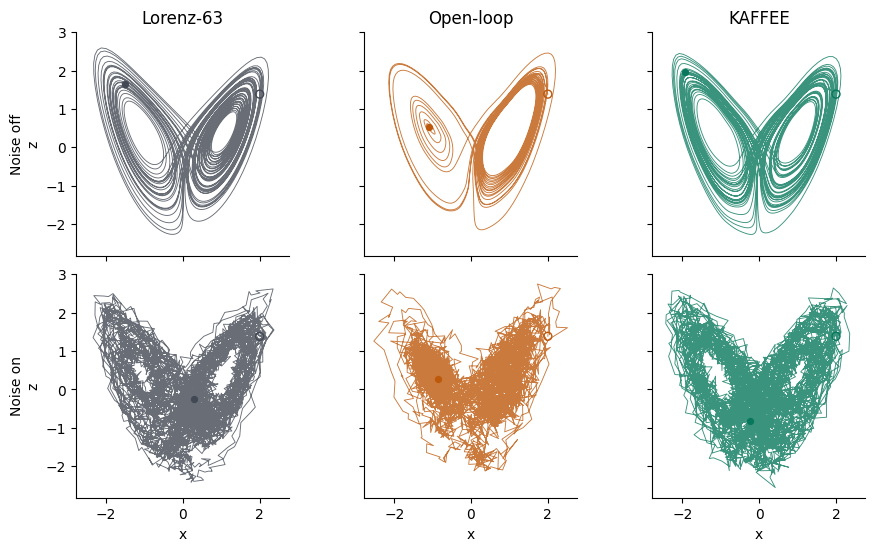

In [34]:
fig, axes = plt.subplots(2, 3, figsize=(9, 5.4), sharex=True, sharey=True,
                         layout="constrained")
colors = {"Lorenz-63": "#424854", "Open-loop": "#bd590b", "KAFFEE": "#08785d"}

for col, (name, pair) in enumerate(paths.items()):
    axes[0, col].set_title(name)
    for ax, path in zip(axes[:, col], pair):
        nonfinite = np.flatnonzero(~np.isfinite(path).all(axis=1))
        if nonfinite.size:
            ax.text(0.5, 0.5, f"Rollout diverged\nat step {nonfinite[0]:,}",
                    ha="center", va="center", transform=ax.transAxes)
            continue
        x, z = path[:, 0], path[:, 2]
        ax.plot(x, z, color=colors[name], lw=0.65, alpha=0.8)
        ax.scatter(x[0], z[0], s=33, facecolors='none', edgecolors=colors[name], zorder=4)
        ax.scatter(x[-1], z[-1], s=18, color=colors[name], zorder=3)
        ax.set_aspect("equal", adjustable="box")
        ax.spines[["top", "right"]].set_visible(False)
    axes[1, col].set_xlabel("x")

axes[0, 0].set_ylabel("Noise off\nz")
axes[1, 0].set_ylabel("Noise on\nz")
plt.show()

In this example, open-loop's noisy rollout "hides" the fact that its deterministic transition has learned stable dynamics, instead of chaos: plotting $x$ against $t$ shows how open-loop spirals toward a fixed point, while KAFFEE keeps generating Lorenz-like dynamics.

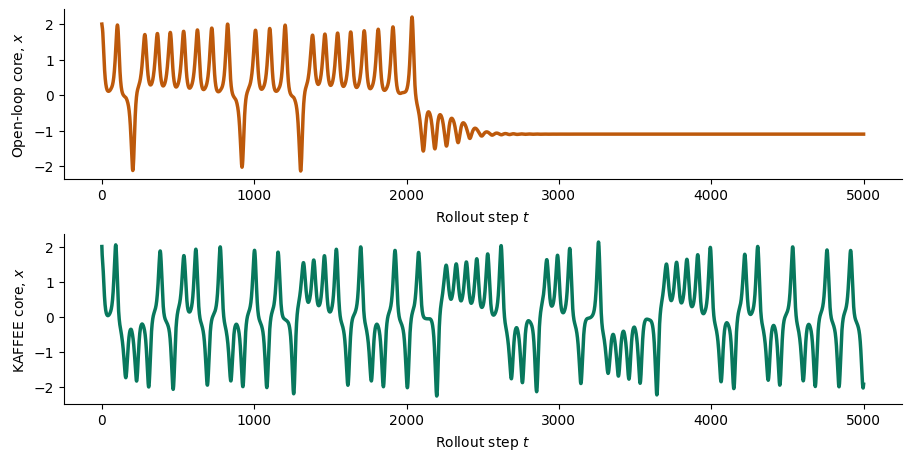

In [35]:
open_loop_core = paths["Open-loop"][0]
kaffee_core = paths["KAFFEE"][0]

fig, axes = plt.subplots(2, 1, figsize=(9, 4.5), layout="constrained")
axes[0].plot(open_loop_core[:, 0], color=colors["Open-loop"], lw=2.5)
axes[0].set_ylabel("Open-loop core, $x$")
axes[1].plot(kaffee_core[:, 0], color=colors["KAFFEE"], lw=2.5)
axes[1].set_ylabel("KAFFEE core, $x$")
axes[0].set_xlabel("Rollout step $t$")
axes[1].set_xlabel("Rollout step $t$")
axes[0].spines[["top", "right"]].set_visible(False)
axes[1].spines[["top", "right"]].set_visible(False)
plt.show()

### Lyapunov spectra of the autonomous cores

For seed 6, the open-loop core approaches a fixed point after a transient, although its shell-on rollout visits both lobes. This outcome varies across training seeds. We can look at the average model behavior by checking the learned median Lyapunov spectrum.

A positive largest Lyapunov exponent means that small perturbations along the most unstable direction grow exponentially on average, a signature of sensitive dependence on initial conditions (and, combined with boundedness in state space, of chaos). A negative exponent expresses contraction along its direction. Lorenz-63 has one expanding, one neutral and one strongly contracting direction. The sum over its exponents is negative (hence it is a dissipative system). 

The trained AL-RNN cores use 30 latent dimensions. For each trained core, we order the corresponding 30 Lyapunov exponents from largest to smallest for each training seed and compare the first three with the deterministic Lorenz-63 spectrum. At each step of a long trajectory, we propagate a tangent basis through the local Jacobian and orthonormalize it by QR decomposition. The Lyapunov spectrum is then the (ordered) average log growth rate of each direction per unit time. Following the paper’s evaluation protocol, we initialize from the clean reference at index 500, discard the first 1,000 steps, and estimate the exponents over the next 30,000 steps (with $\Delta t=0.01$).

In [36]:
import pandas as pd
from data.lorenz63 import standardize_raw_series
from experiments.lorenz63_main import load_lorenz63_eval_bundle
from metrics import robust_se_of_median

evaluation = config["evaluation"]
le_start = evaluation["core_start_index"]
burn = evaluation["lyapunov_burn_steps"]
scored = evaluation["lyapunov_rollout_steps"]
dt = config["system"]["dt"]
clean_raw = load_lorenz63_eval_bundle(config)["test_core_raw"]

true_spectrum = l63._l63_clean_spectrum(clean_raw, start=le_start, burn=burn, roll=scored, dt=dt)
ranks = [1, 2, 3]
reference = pd.Series(np.sort(true_spectrum)[::-1], index=ranks)
reference.index.name = "rank"

In [37]:
sweep = config["seed_sweep"]
seeds = range(sweep["start_seed"], sweep["start_seed"] + sweep["count"])
rows = []
for seed in seeds:
    prior = l63._load_core_checkpoint(root / "models/lorenz63_main_cores", seed)
    initial_obs = standardize_raw_series(clean_raw[le_start:le_start + 1], l63._core_standardizer(prior))[0]
    for method in methods.values():
        core_model = l63._core_from_shell(load_fitted_model(seed, method), cpu)
        # The core model returns rates per discrete time step, which needs to be divided by the time step to get rates per time unit.
        spectrum = core_model.lyapunov_spectrum(initial_obs, steps=burn + scored, burn=burn) / dt
        for rank, exponent in enumerate(np.sort(spectrum)[::-1], start=1):
            rows.append((seed, method, rank, exponent))

spectra = pd.DataFrame(rows, columns=["seed", "model", "rank", "exponent"])
fitted = spectra.loc[spectra["rank"] <= 3]
summary = fitted.groupby(["model", "rank"])["exponent"].agg(median="median", se=robust_se_of_median)

Now plot the median LE spectra reconstruction, with error bars given by the standard error of the median.

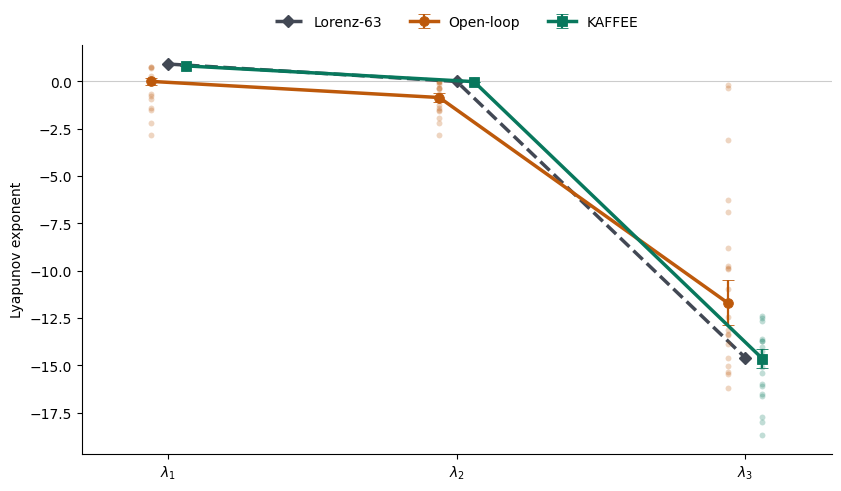

In [38]:
fig, ax = plt.subplots(figsize=(8.3, 4.8), layout="constrained")
ranks = [1, 2, 3]
ax.axhline(0, color="0.8", lw=0.8)
ax.plot(ranks, reference.loc[ranks], "D--", color=colors["Lorenz-63"], ms=6, lw=2.5, label="Lorenz-63")

for name, marker, offset in [("Open-loop", "o", -0.06), ("KAFFEE", "s", 0.06)]:
    method = methods[name]
    x = np.asarray(ranks) + offset
    values = summary.loc[method].loc[ranks]
    per_seed = fitted[fitted["model"] == method]
    ax.scatter(per_seed["rank"] + offset, per_seed["exponent"], 
               s=18, alpha=0.25, color=colors[name], linewidths=0, zorder=2) # horizontal offset for visibility
    ax.errorbar(x, values["median"], yerr=values["se"], fmt=marker + "-",
                color=colors[name], ms=7, lw=2.5, elinewidth=1.6, capsize=4,
                markeredgewidth=0.6, zorder=3, label=name)

ax.set_xticks(ranks, [rf"$\lambda_{rank}$" for rank in ranks])
ax.set_xlim(0.7, 3.3)
ax.set_ylabel("Lyapunov exponent")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncols=3, frameon=False)
plt.show()

KAFFEE’s median spectrum has a positive first exponent, a second close to zero, and a third near −14.6, all close to the true Lorenz-63. The open-loop core models have a near-zero median leading exponent and a more negative second exponent, so these models learn an attenuated expansion or even stable instead of unstable (i.e., chaotic) dynamics.